# Proyecto final: Data Analytics - SynthData

Alumno: Gustavo Mauricio Morales

Comisión: 26216

Etapas: 1 (Recopilación y Preparación), 2 (Preprocesamiento y Limpieza), 3 (análisis de datos) y 4 (visualización de datos)

## Etapa 1: Recopilación y preparación de datos

### 1. Carga de DataFrames
Cargamos los datasets (archivos .csv) desde el repositorio de GitHub. El método anterior con Google Drive se conserva comentado a continuación.

In [1]:
import pandas as pd
import numpy as np

# Código anterior con Google Drive (conservado como referencia):
#from google.colab import drive

# 1. Montar Google Drive
#drive.mount('/content/drive')

# 2. Definir la ruta donde subiste los CSV
#path = '/content/drive/MyDrive/MoralesGustavo-Comisión 26216-TPI Data Analytics/'

# 3. Carga de datasets desde Drive
#df_ventas = pd.read_csv(path + 'ventas.csv')
#df_marketing = pd.read_csv(path + 'marketing.csv')
#df_clientes = pd.read_csv(path + 'clientes.csv')


# 1. Definir la ruta donde subiste los CSV (GitHub)
path = "https://raw.githubusercontent.com/gmmorales/Proyecto_final_Data_Analytics_SynthData/refs/heads/develop/datasets/"

# 2. Carga de datasets desde GitHub
df_ventas = pd.read_csv(path + 'ventas.csv')
df_marketing = pd.read_csv(path + 'marketing.csv')
df_clientes = pd.read_csv(path + 'clientes.csv')

print("Datasets cargados exitosamente")

Datasets cargados exitosamente


### 2. Script básico de ventas (Python puro / Variables y Operadores)
Realizamos un cálculo con estructuras primitivas de Python para evaluar métricas clave sin depender directamente de Pandas.

In [4]:
# Definición de variables de un período de ventas
monto_mes_1 = 129604.99
monto_mes_2 = 118672.44
monto_mes_3 = 136779.15

# Operaciones
total_trimestre = monto_mes_1 + monto_mes_2 + monto_mes_3
promedio_mensual = total_trimestre / 3

print(f"Total de ventas del trimestre: ${total_trimestre:,.2f}")
print(f"Promedio de ventas mensual: ${promedio_mensual:,.2f}")

Total de ventas del trimestre: $385,056.58
Promedio de ventas mensual: $128,352.19


### 3. Estructuras de datos: Listas vs. Diccionarios
Decisión técnica: Para almacenar registros de ventas individuales con múltiples atributos (producto, precio, cantidad), la estructura óptima es una lista de diccionarios.

*   Justificación: Los diccionarios proveen acceso explícito y semántico por clave (ej. registro['precio']), mientras que la lista permite iterar secuencialmente sobre el conjunto de transacciones.





In [5]:
# Ejemplo de almacenamiento estruturado
ventas_list = [
    {"producto": "Proyector", "precio": 88.17, "cantidad": 9},
    {"producto": "Lámpara de mesa", "precio": 105.10, "cantidad": 5},
    {"producto": "Horno eléctrico", "precio": 35.35, "cantidad": 9}
]

# Cálculo de ingresos totales iterando sobre la estructura
ingreso_total_estructurado = sum(item["precio"] * item["cantidad"] for item in ventas_list)
print(f"Ingreso Total Calculado: ${ingreso_total_estructurado:,.2f}")

Ingreso Total Calculado: $1,637.18


### 4 y 5. Exploración inicial y Diagnóstico de Calidad de Datos (EDA)
Inspeccionamos volumen, tipos de datos, presencia de nulos y registros duplicados.

In [6]:
print("--- DATAFRAME VENTAS ---")
print(df_ventas.info())
print("\nRegistros nulos en Ventas:\n", df_ventas.isnull().sum())
print(f"Filas duplicadas en Ventas: {df_ventas.duplicated().sum()}")

print("\n--- DATAFRAME MARKETING ---")
print(df_marketing.info())
print("\nRegistros nulos en Marketing:\n", df_marketing.isnull().sum())
print(f"Filas duplicadas en Marketing: {df_marketing.duplicated().sum()}")

--- DATAFRAME VENTAS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3035 entries, 0 to 3034
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id_venta     3035 non-null   int64  
 1   producto     3035 non-null   object 
 2   precio       3033 non-null   object 
 3   cantidad     3033 non-null   float64
 4   fecha_venta  3035 non-null   object 
 5   categoria    3035 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 142.4+ KB
None

Registros nulos en Ventas:
 id_venta       0
producto       0
precio         2
cantidad       2
fecha_venta    0
categoria      0
dtype: int64
Filas duplicadas en Ventas: 35

--- DATAFRAME MARKETING ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_campanha   90 non-null     int64  
 1   producto      90 non-nul

Informe de Calidad Inicial:

*   df_ventas: Contiene 3.035 registros. Se identifican 35 filas duplicadas, 2 valores nulos en la columna precio y 2 nulos en cantidad. Además, la columna precio viene codificada como string con el carácter $.
*   df_marketing: Contiene 90 registros sin nulos ni duplicados.

## Etapa 2: Preprocesamiento y limpieza de datos

### 1. Limpieza de datos (Data Cleansing)
Sanitizamos la columna precio, eliminamos nulos y removemos registros duplicados.

In [7]:
# 1. Copia de respaldo
df_ventas_clean = df_ventas.copy()

# 2. Eliminación de duplicados
df_ventas_clean = df_ventas_clean.drop_duplicates()

# 3. Limpieza del carácter '$' y conversión a float
df_ventas_clean['precio'] = df_ventas_clean['precio'].astype(str).str.replace('$', '', regex=False).str.strip()
df_ventas_clean['precio'] = pd.to_numeric(df_ventas_clean['precio'], errors='coerce')

# 4. Eliminación de filas con nulos críticos
df_ventas_clean = df_ventas_clean.dropna(subset=['precio', 'cantidad'])

# 5. Formateo de fecha y columna calculada de ingreso
df_ventas_clean['fecha_venta'] = pd.to_datetime(df_ventas_clean['fecha_venta'], format='%d/%m/%Y')
df_ventas_clean['ingreso_total'] = df_ventas_clean['precio'] * df_ventas_clean['cantidad']

print(f"Registros originales: {len(df_ventas)} | Registros limpios: {len(df_ventas_clean)}")

Registros originales: 3035 | Registros limpios: 2998


### 2. Transformación de datos: Productos de alto rendimiento
Filtramos los productos cuya venta individual o ingreso total supere el percentil o umbral de alto rendimiento (ej. ingresos por transacción superiores a $500).

In [8]:
# Filtrado de transacciones de alto rendimiento (> $500)
umbral = 500
df_alto_rendimiento = df_ventas_clean[df_ventas_clean['ingreso_total'] > umbral].copy()

print(f"Transacciones de alto rendimiento ( > ${umbral} ): {len(df_alto_rendimiento)}")
df_alto_rendimiento.head()

Transacciones de alto rendimiento ( > $500 ): 1229


,id_venta,producto,precio,cantidad,fecha_venta,categoria,ingreso_total
1,811,Lámpara de mesa,105.10,5.0,2024-01-02,Decoración,525.50
3,1372,Heladera,114.35,8.0,2024-01-02,Electrodomésticos,914.80
7,2959,Proyector,88.17,9.0,2024-01-02,Electrónica,793.53
8,318,Rincón de plantas,79.86,11.0,2024-01-03,Decoración,878.46
9,419,Candelabro,66.11,8.0,2024-01-03,Decoración,528.88


### 3. Agregación de ventas por categoría
Agrupamos por categoría para analizar los ingresos acumulados e identificamos la categoría más rentable.

In [9]:
resumen_categoria = df_ventas_clean.groupby('categoria').agg(
    ingresos_totales=('ingreso_total', 'sum'),
    precio_promedio=('precio', 'mean'),
    unidades_vendidas=('cantidad', 'sum'),
    total_transacciones=('id_venta', 'count')
).reset_index()

resumen_categoria['ingresos_totales'] = resumen_categoria['ingresos_totales'].round(2)
print(resumen_categoria)

           categoria  ingresos_totales  precio_promedio  unidades_vendidas  \
0         Decoración         479216.09         74.09800             6490.0   
1  Electrodomésticos         505299.63         76.52096             6592.0   
2        Electrónica         482577.80         75.25492             6413.0   

   total_transacciones  
0                 1000  
1                 1000  
2                  998  


### 4. Integración de datos (Ventas + Marketing)
Realizamos un merge entre los datasets de ventas y campañas de marketing asociando por la clave común producto.

In [10]:
df_integrado = pd.merge(
    df_ventas_clean,
    df_marketing,
    on='producto',
    how='inner',
    suffixes=('_venta', '_marketing')
)

print(f"Shape del dataset integrado: {df_integrado.shape}")
df_integrado[['id_venta', 'producto', 'categoria', 'ingreso_total', 'canal', 'costo']].head()

Shape del dataset integrado: (8994, 12)


,id_venta,producto,categoria,ingreso_total,canal,costo
0,792,Cuadro decorativo,Decoración,349.7,RRSS,5.27
1,792,Cuadro decorativo,Decoración,349.7,Email,5.28
2,792,Cuadro decorativo,Decoración,349.7,TV,5.30
3,811,Lámpara de mesa,Decoración,525.5,Email,5.54
4,811,Lámpara de mesa,Decoración,525.5,RRSS,5.88


## Etapa 3: Análisis de datos

### 1. Estadística descriptiva
Calculamos las medidas de tendencia central (media, mediana, moda) y de dispersión (desviación estándar, varianza, rango intercuartílico y extremos) sobre las variables numéricas clave del conjunto de ventas limpio (precio, cantidad, ingreso_total).

In [11]:
# Selección de variables numéricas relevantes
cols_num = ['precio', 'cantidad', 'ingreso_total']

# Construcción de tabla resumen de estadística descriptiva
estadisticas_desc = pd.DataFrame(index=cols_num)
estadisticas_desc['Media'] = df_ventas_clean[cols_num].mean()
estadisticas_desc['Mediana'] = df_ventas_clean[cols_num].median()
estadisticas_desc['Moda'] = [df_ventas_clean[col].mode().iloc[0] for col in cols_num]
estadisticas_desc['Desv_Estandar'] = df_ventas_clean[cols_num].std()
estadisticas_desc['Varianza'] = df_ventas_clean[cols_num].var()
estadisticas_desc['Minimo'] = df_ventas_clean[cols_num].min()
estadisticas_desc['Q1 (25%)'] = df_ventas_clean[cols_num].quantile(0.25)
estadisticas_desc['Q3 (75%)'] = df_ventas_clean[cols_num].quantile(0.75)
estadisticas_desc['Maximo'] = df_ventas_clean[cols_num].max()
estadisticas_desc['IQR (Rango Intercuartílico)'] = estadisticas_desc['Q3 (75%)'] - estadisticas_desc['Q1 (25%)']

print("--- INFORME DE ESTADÍSTICA DESCRIPTIVA (VENTAS) ---")
display(estadisticas_desc.round(2))

--- INFORME DE ESTADÍSTICA DESCRIPTIVA (VENTAS) ---


,Media,Mediana,Moda,Desv_Estandar,Varianza,Minimo,Q1 (25%),Q3 (75%),Maximo,IQR (Rango Intercuartílico)
precio,75.29,75.20,29.77,28.74,825.76,26.0,50.03,100.07,124.97,50.04
cantidad,6.50,7.00,11.00,3.46,11.94,1.0,3.00,9.00,12.00,6.00
ingreso_total,489.36,418.06,345.33,334.28,111744.33,26.3,220.92,709.92,1488.12,489.00


Informe de Estadística Descriptiva

- **Precio Unitario:** Presenta una distribución altamente simétrica con una media de $\$75.29$ y una mediana de $\$75.20$ (desviación estándar de $\$28.74$, rango de $\$26.00$ a $\$124.97$).
- **Cantidad por Transacción:** El volumen promedio por operación es de $6.50$ unidades (mediana de $7.00$ unidades, IQR de $6.00$), oscilando entre $1$ y $12$ unidades.
- **Ingreso Total por Venta:** Muestra una media de $\$489.36$ frente a una mediana de $\$418.06$. Esta diferencia refleja una asimetría positiva (sesgo a la derecha), traccionada por operaciones de alto volumen y precio que alcanzan un máximo de $\$1,488.12$, con una dispersión elevada ($\sigma = \$334.28$, $\text{IQR} = \$489.00$).

### 2. Análisis Exploratorio de Datos (EDA)
Exploramos la evolución temporal de las ventas a nivel mensual y el comportamiento por categoría de producto para identificar estacionalidad, picos de demanda y patrones de facturación.

--- EVOLUCIÓN MENSUAL DE VENTAS (2024) ---


,mes,ingresos_totales,transacciones,ticket_promedio
0,2024-01,129604.99,268,483.60
1,2024-02,118672.44,248,478.52
2,2024-03,136779.15,265,516.15
3,2024-04,128430.69,275,467.02
4,2024-05,143727.25,275,522.64
5,2024-06,108480.17,221,490.86
6,2024-07,116229.97,243,478.31
7,2024-08,119680.15,254,471.18
8,2024-09,115787.85,241,480.45
9,2024-10,112117.13,230,487.47


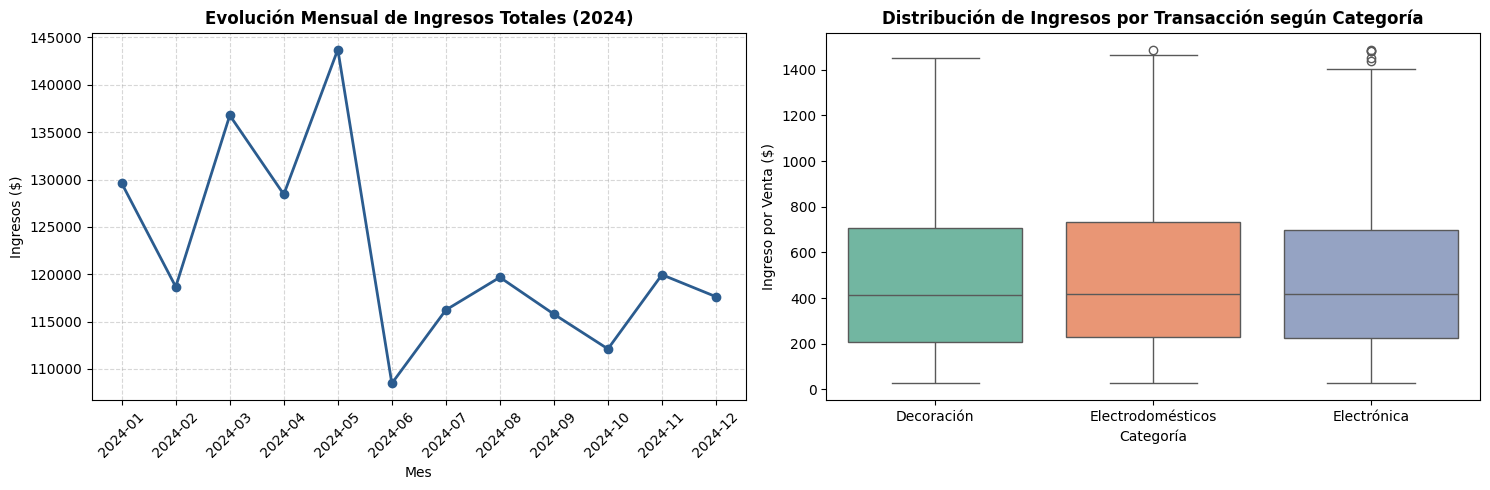

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extracción de período mensual
df_ventas_clean['mes'] = df_ventas_clean['fecha_venta'].dt.to_period('M').astype(str)

# Agregación mensual
ventas_mensuales = df_ventas_clean.groupby('mes').agg(
    ingresos_totales=('ingreso_total', 'sum'),
    transacciones=('id_venta', 'count'),
    ticket_promedio=('ingreso_total', 'mean')
).reset_index()

print("--- EVOLUCIÓN MENSUAL DE VENTAS (2024) ---")
display(ventas_mensuales.round(2))

# Visualización exploratoria rápida (Tendencia mensual y distribución por categoría)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Tendencia mensual de ingresos
axes[0].plot(ventas_mensuales['mes'], ventas_mensuales['ingresos_totales'], marker='o', color='#2b5c8f', linewidth=2)
axes[0].set_title('Evolución Mensual de Ingresos Totales (2024)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Mes')
axes[0].set_ylabel('Ingresos ($)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Gráfico 2: Distribución de ingresos por categoría
sns.boxplot(data=df_ventas_clean, x='categoria', y='ingreso_total', ax=axes[1], palette='Set2', hue='categoria', legend=False)
axes[1].set_title('Distribución de Ingresos por Transacción según Categoría', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Categoría')
axes[1].set_ylabel('Ingreso por Venta ($)')

plt.tight_layout()
plt.show()

Patrones Detectados en el EDA

* **Estacionalidad Primer Semestre vs. Segundo Semestre:** El pico máximo de facturación ocurre en mayo de 2024 ($\$143,727.25$ en $275$ transacciones, con el ticket promedio más alto del año: $\$522.64$), seguido por marzo ($\$136,779.15$). En contraste, junio registra el piso anual ($\$108,480.17$), estabilizándose el segundo semestre en un rango de $\$112\text{k} - \$120\text{k}$ mensuales.

* **Equilibrio entre Categorías:** Las tres categorías muestran distribuciones medianas y rangos intercuartílicos homogéneos, destacando Electrodomésticos ligeramente por encima en volumen total ($\$505,299.63$).

### 3. Análisis de Correlación
Evaluamos la relación lineal (coeficiente de Pearson) tanto a nivel de transacción individual (precio, cantidad, ingreso_total) como a nivel agregado por producto cruzando inversión en marketing contra ingresos generados.

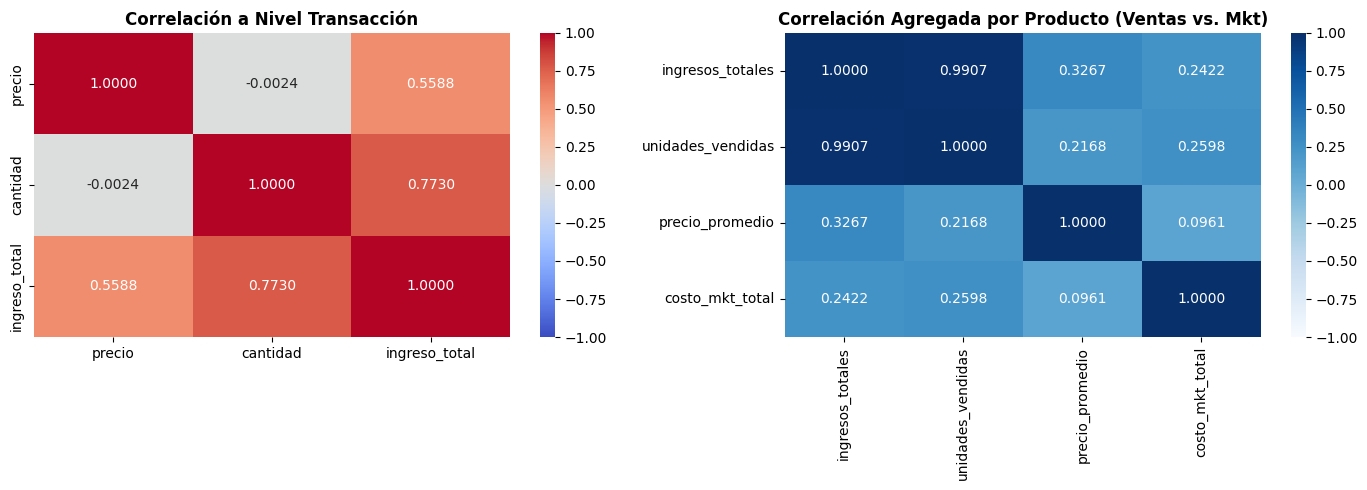

In [13]:
# Matriz de correlación a nivel transaccional
corr_transacciones = df_ventas_clean[['precio', 'cantidad', 'ingreso_total']].corr()

# Agregación por producto para evaluar impacto de marketing
ventas_prod = df_ventas_clean.groupby(['producto', 'categoria']).agg(
    ingresos_totales=('ingreso_total', 'sum'),
    unidades_vendidas=('cantidad', 'sum'),
    precio_promedio=('precio', 'mean'),
    transacciones=('id_venta', 'count')
).reset_index()

mkt_prod = df_marketing.groupby('producto').agg(
    costo_mkt_total=('costo', 'sum'),
    campanhas_totales=('id_campanha', 'count'),
    canales=('canal', lambda x: ', '.join(sorted(x.unique())))
).reset_index()

df_prod_mkt = pd.merge(ventas_prod, mkt_prod, on='producto', how='inner')
corr_mkt = df_prod_mkt[['ingresos_totales', 'unidades_vendidas', 'precio_promedio', 'costo_mkt_total']].corr()

# Visualización de matrices de correlación
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(corr_transacciones, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.4f', ax=axes[0])
axes[0].set_title('Correlación a Nivel Transacción', fontsize=12, fontweight='bold')

sns.heatmap(corr_mkt, annot=True, cmap='Blues', vmin=-1, vmax=1, fmt='.4f', ax=axes[1])
axes[1].set_title('Correlación Agregada por Producto (Ventas vs. Mkt)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

Interpretación de Correlaciones

* **Precio vs. Cantidad ($r = -0.0024$):** Correlación lineal prácticamente nula. El volumen de unidades adquiridas por transacción no disminuye cuando aumenta el precio unitario, evidenciando baja elasticidad-precio en el catálogo.

* **Impulsores del Ingreso:** La variable cantidad ($r = 0.7730$) tiene mayor peso explicativo sobre el `ingreso_total` de cada venta que el precio ($r = 0.5588$).

* **Inversión en Marketing vs. Ingresos por Producto ($r = 0.2422$):** Existe una correlación positiva débil. Todos los productos recibieron exactamente 3 campañas (Email, RRSS y TV) con presupuestos acotados ($\$13.27$ a $\$18.16$ acumulados), lo que sugiere que el rendimiento comercial depende más de la rotación orgánica del producto que de las variaciones marginales de pauta.

### 4. Consolidación de datos
Construimos un conjunto de datos final consolidado por producto (df_consolidado_final) integrando métricas de ventas, participación porcentual sobre ingresos totales, inversión acumulada en marketing, beneficio neto post-marketing y retorno sobre la inversión publicitaria (ROAS), dejándolo listo para la etapa de visualización y reporte ejecutivo.

In [14]:
# Construcción del dataset consolidado final
df_consolidado_final = df_prod_mkt.copy()

# Cálculo de KPIs ejecutivos
total_ingresos_empresa = df_consolidado_final['ingresos_totales'].sum()
df_consolidado_final['participacion_ingresos_%'] = (df_consolidado_final['ingresos_totales'] / total_ingresos_empresa * 100).round(2)
df_consolidado_final['ingreso_neto_mkt'] = (df_consolidado_final['ingresos_totales'] - df_consolidado_final['costo_mkt_total']).round(2)
df_consolidado_final['roas'] = (df_consolidado_final['ingresos_totales'] / df_consolidado_final['costo_mkt_total']).round(2)

# Ordenar de mayor a menor ingreso
df_consolidado_final = df_consolidado_final.sort_values(by='ingresos_totales', ascending=False).reset_index(drop=True)

# Redondeo de columnas monetarias y promedios
df_consolidado_final['ingresos_totales'] = df_consolidado_final['ingresos_totales'].round(2)
df_consolidado_final['precio_promedio'] = df_consolidado_final['precio_promedio'].round(2)
df_consolidado_final['costo_mkt_total'] = df_consolidado_final['costo_mkt_total'].round(2)

print(f"Dataset consolidado generado con {df_consolidado_final.shape[0]} productos y {df_consolidado_final.shape[1]} métricas.")
display(df_consolidado_final.head(10))

# Opcional: Exportar dataset consolidado a Drive para respaldo
# df_consolidado_final.to_csv(path + 'consolidado_final_synthdata.csv', index=False)

Dataset consolidado generado con 30 productos y 12 métricas.


,producto,categoria,ingresos_totales,unidades_vendidas,precio_promedio,transacciones,costo_mkt_total,campanhas_totales,canales,participacion_ingresos_%,ingreso_neto_mkt,roas
0,Lámpara de mesa,Decoración,82276.38,1112.0,72.72,176,15.93,3,"Email, RRSS, TV",5.61,82260.45,5164.87
1,Auriculares,Electrónica,74175.58,958.0,76.30,143,15.24,3,"Email, RRSS, TV",5.06,74160.34,4867.16
2,Microondas,Electrodomésticos,72562.89,912.0,79.18,135,14.19,3,"Email, RRSS, TV",4.95,72548.70,5113.66
3,Cafetera,Electrodomésticos,59607.31,765.0,79.05,117,18.16,3,"Email, RRSS, TV",4.06,59589.15,3282.34
4,Cuadro decorativo,Decoración,54297.60,726.0,74.58,100,15.85,3,"Email, RRSS, TV",3.70,54281.75,3425.72
5,Smartphone,Electrónica,54132.44,665.0,81.40,101,15.80,3,"Email, RRSS, TV",3.69,54116.64,3426.10
6,Secadora,Electrodomésticos,52115.45,696.0,73.34,100,14.59,3,"Email, RRSS, TV",3.55,52100.86,3572.00
7,Jarrón decorativo,Decoración,51130.88,672.0,74.53,100,13.27,3,"Email, RRSS, TV",3.49,51117.61,3853.12
8,Batidora,Electrodomésticos,50979.20,672.0,77.54,100,15.28,3,"Email, RRSS, TV",3.47,50963.92,3336.34
9,Rincón de plantas,Decoración,50456.45,691.0,74.82,101,16.45,3,"Email, RRSS, TV",3.44,50440.00,3067.26


## Etapa 4: Visualización de datos

### 1. Visualización con Matplotlib
Desarrollamos gráficos fundamentales (líneas, barras y dispersión) utilizando matplotlib.pyplot para representar la evolución temporal de las ventas (mensual y trimestral) y la relación entre precio unitario e ingreso por transacción.

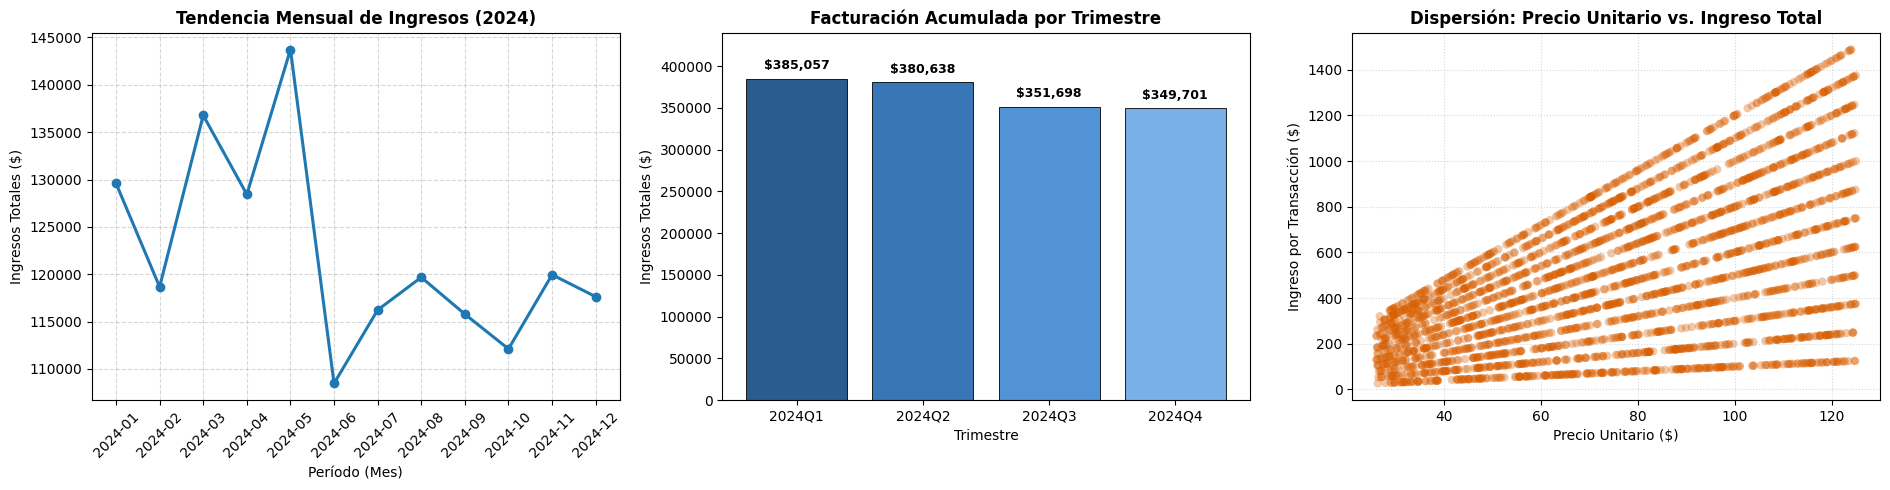

In [15]:
import matplotlib.pyplot as plt

# Preparación de cortes temporales
df_ventas_clean['trimestre'] = df_ventas_clean['fecha_venta'].dt.to_period('Q').astype(str)
ventas_trimestrales = df_ventas_clean.groupby('trimestre')['ingreso_total'].sum().reset_index()

# Configuración de figura multipanel (1 fila, 3 columnas)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# 1. Gráfico de Líneas: Evolución Mensual
axes[0].plot(ventas_mensuales['mes'], ventas_mensuales['ingresos_totales'], marker='o', color='#1f77b4', linewidth=2.2)
axes[0].set_title('Tendencia Mensual de Ingresos (2024)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Período (Mes)')
axes[0].set_ylabel('Ingresos Totales ($)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Gráfico de Barras: Ingresos por Trimestre
bars = axes[1].bar(ventas_trimestrales['trimestre'], ventas_trimestrales['ingreso_total'], color=['#2b5c8f', '#3876b5', '#5293d6', '#7ab0e8'], edgecolor='black', linewidth=0.6)
axes[1].set_title('Facturación Acumulada por Trimestre', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Trimestre')
axes[1].set_ylabel('Ingresos Totales ($)')
axes[1].set_ylim(0, 440000)
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 8000, f'${yval:,.0f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# 3. Gráfico de Dispersión: Precio Unitario vs. Ingreso Total
axes[2].scatter(df_ventas_clean['precio'], df_ventas_clean['ingreso_total'], alpha=0.35, color='#d95f02', edgecolors='none')
axes[2].set_title('Dispersión: Precio Unitario vs. Ingreso Total', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Precio Unitario ($)')
axes[2].set_ylabel('Ingreso por Transacción ($)')
axes[2].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

Observaciones sobre Visualizaciones Base (Matplotlib)

* **Desempeño Trimestral:** El primer trimestre (2024Q1: $\$385,056.58$) y el segundo trimestre (2024Q2: $\$380,638.11$) concentran el $52.19\%$ de la facturación anual, frente a una leve retracción en 2024Q3 ($\$351,697.97$) y 2024Q4 ($\$349,700.86$).

* **Patrón de Dispersión:** Las franjas diagonales visibles en el gráfico de dispersión corresponden a los niveles discretos de cantidad comprada ($1$ a $12$ unidades), confirmando que a mayor precio unitario la pendiente del ingreso crece linealmente por cada nivel de volumen.

### 2. Visualización avanzada con Seaborn
Aplicamos estilos estadísticos avanzados y paletas perceptualmente uniformes mediante seaborn para analizar densidades de distribución por categoría (violinplot), regresiones lineales entre inversión publicitaria e ingresos (regplot) y rankings de productos líderes (barplot).

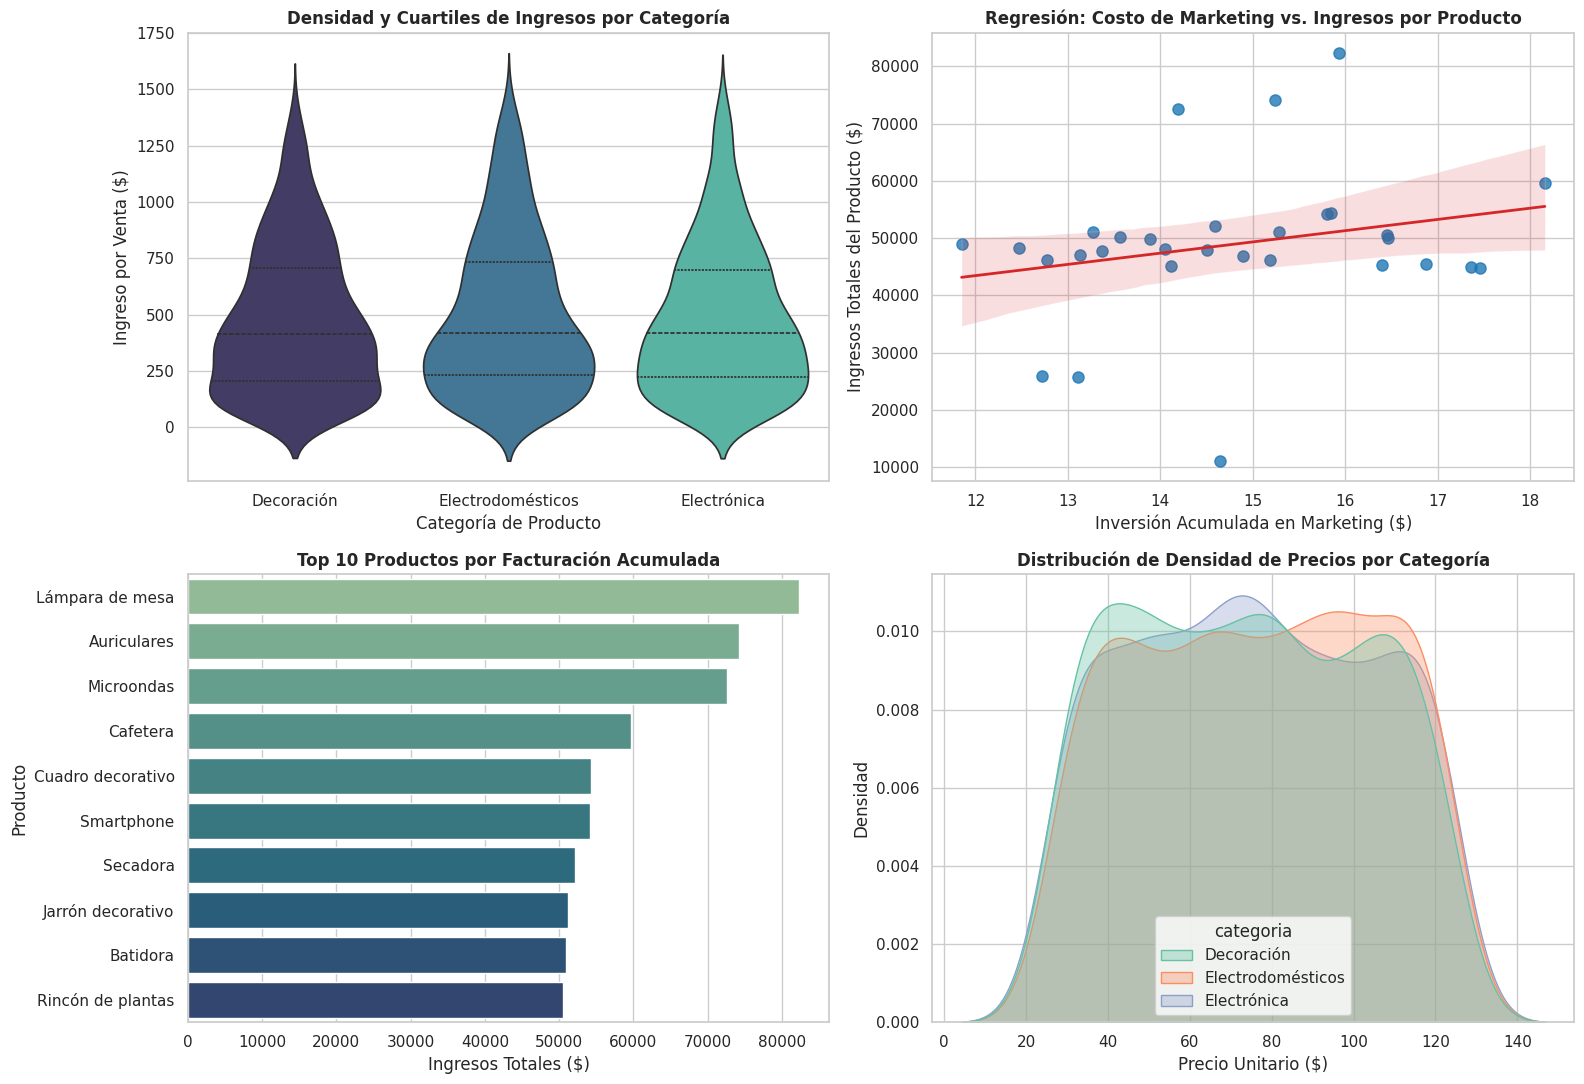

In [16]:
import seaborn as sns

# Configuración estética global
sns.set_theme(style="whitegrid", palette="viridis")

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Violin Plot: Densidad y cuartiles de ingreso por categoría
sns.violinplot(
    data=df_ventas_clean, x='categoria', y='ingreso_total',
    ax=axes[0, 0], palette='mako', hue='categoria', legend=False, inner='quartile'
)
axes[0, 0].set_title('Densidad y Cuartiles de Ingresos por Categoría', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Categoría de Producto')
axes[0, 0].set_ylabel('Ingreso por Venta ($)')

# 2. Regplot: Relación Inversión Marketing vs. Ingresos Totales por Producto
sns.regplot(
    data=df_consolidado_final, x='costo_mkt_total', y='ingresos_totales',
    ax=axes[0, 1], scatter_kws={'s': 65, 'alpha': 0.8, 'color': '#1f77b4'}, line_kws={'color': '#d62728', 'linewidth': 2}
)
axes[0, 1].set_title('Regresión: Costo de Marketing vs. Ingresos por Producto', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Inversión Acumulada en Marketing ($)')
axes[0, 1].set_ylabel('Ingresos Totales del Producto ($)')

# 3. Barplot Horizontal: Top 10 Productos por Ingresos Totales
top10_prod = df_consolidado_final.head(10)
sns.barplot(
    data=top10_prod, x='ingresos_totales', y='producto',
    ax=axes[1, 0], palette='crest', hue='producto', legend=False
)
axes[1, 0].set_title('Top 10 Productos por Facturación Acumulada', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Ingresos Totales ($)')
axes[1, 0].set_ylabel('Producto')

# 4. KDE Plot: Distribución de densidad de precios por categoría
sns.kdeplot(
    data=df_ventas_clean, x='precio', hue='categoria',
    fill=True, common_norm=False, alpha=0.35, ax=axes[1, 1], palette='Set2'
)
axes[1, 1].set_title('Distribución de Densidad de Precios por Categoría', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Precio Unitario ($)')
axes[1, 1].set_ylabel('Densidad')

plt.tight_layout()
plt.show()

### 3. Visualización interactiva con Plotly
Construimos un Dashboard Interactivo Multipanel con plotly.subplots que integra cuatro vistas dinámicas con hover tooltips detallados: evolución temporal mensual, participación por categoría, matriz de rentabilidad (Ingresos vs. ROAS e inversión en marketing) y ranking de productos estrella.

In [17]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Preparación de agregados para el dashboard
cat_summary = df_consolidado_final.groupby('categoria').agg(
    ingresos=('ingresos_totales', 'sum'),
    unidades=('unidades_vendidas', 'sum'),
    roas_promedio=('roas', 'mean')
).reset_index()

top10_plotly = df_consolidado_final.head(10).sort_values(by='ingresos_totales', ascending=True)

# Creación de estructura de Dashboard (2x2)
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        'Evolución Mensual de Ingresos ($)',
        'Participación de Ingresos por Categoría',
        'Matriz de Eficiencia: Ingresos vs. Costo Mkt (Tamaño = ROAS)',
        'Top 10 Productos por Facturación ($)'
    ),
    specs=[
        [{"type": "scatter"}, {"type": "pie"}],
        [{"type": "scatter"}, {"type": "bar"}]
    ],
    vertical_spacing=0.14,
    horizontal_spacing=0.12
)

# Panel 1: Serie Temporal Mensual
fig.add_trace(
    go.Scatter(
        x=ventas_mensuales['mes'],
        y=ventas_mensuales['ingresos_totales'],
        mode='lines+markers',
        name='Ingresos Mensuales',
        line=dict(color='#1f77b4', width=3),
        marker=dict(size=8),
        hovertemplate='<b>Mes:</b> %{x}<br><b>Ingresos:</b> $%{y:,.2f}<extra></extra>'
    ),
    row=1, col=1
)

# Panel 2: Gráfico de Torta / Dona por Categoría
fig.add_trace(
    go.Pie(
        labels=cat_summary['categoria'],
        values=cat_summary['ingresos'],
        hole=0.45,
        name='Categorías',
        marker=dict(colors=['#2b5c8f', '#38a3a5', '#57cc99']),
        hovertemplate='<b>%{label}</b><br>Ingresos: $%{value:,.2f}<br>Participación: %{percent}<extra></extra>'
    ),
    row=1, col=2
)

# Panel 3: Burbujas (Costo Mkt vs Ingresos, tamaño por ROAS)
fig.add_trace(
    go.Scatter(
        x=df_consolidado_final['costo_mkt_total'],
        y=df_consolidado_final['ingresos_totales'],
        mode='markers',
        name='Productos',
        text=df_consolidado_final['producto'],
        marker=dict(
            size=df_consolidado_final['roas'] / 180,
            color=df_consolidado_final['roas'],
            colorscale='Viridis',
            showscale=True,
            colorbar=dict(title='ROAS', x=0.46, y=0.22, len=0.4)
        ),
        hovertemplate='<b>%{text}</b><br>Costo Mkt: $%{x:.2f}<br>Ingresos: $%{y:,.2f}<extra></extra>'
    ),
    row=2, col=1
)

# Panel 4: Barras Horizontales Top 10 Productos
fig.add_trace(
    go.Bar(
        x=top10_plotly['ingresos_totales'],
        y=top10_plotly['producto'],
        orientation='h',
        name='Top 10 Productos',
        marker=dict(color='#2b5c8f'),
        hovertemplate='<b>%{y}</b><br>Ingresos: $%{x:,.2f}<extra></extra>'
    ),
    row=2, col=2
)

# Ajustes globales de diseño
fig.update_layout(
    title_text='<b>SynthData - Dashboard Ejecutivo de Ventas y Marketing (2024)</b>',
    title_x=0.5,
    height=820,
    showlegend=False,
    template='plotly_white'
)

fig.show()

4. Presentación final: Síntesis Ejecutiva para el Panel de SynthData

Resumen ejecutivo estructurado para la exposición ante el comité evaluador de SynthData, sintetizando metodología, hallazgos críticos y recomendaciones accionables:

1. Calidad e Integridad de Datos (Etapas 1 y 2)
* Se auditaron $3,035$ registros transaccionales, depurando $35$ registros duplicados y $2$ registros con valores nulos críticos, alcanzando una base limpia de $2,998$ transacciones válidas por un total anual de $\$1,467,093.52$.
* El $41.0\%$ de las operaciones ($1,229$ ventas) corresponde a transacciones de alto rendimiento ($> \$500$).

2. Comportamiento Comercial y Estacionalidad (Etapa 3)
* **Ticket Promedio:** $\$489.36$ (mediana $\$418.06$), impulsado principalmente por el volumen de unidades por operación ($r = 0.7730$) más que por el precio unitario ($r = 0.5588$).
* **Inelasticidad al Precio:** La correlación entre precio y cantidad es nula ($r = -0.0024$), lo que habilita estrategias de optimización de márgenes sin pérdida de volumen.
* **Estacionalidad:** El primer semestre lidera la facturación con pico en mayo ($\$143,727.25$) y valle en junio ($\$108,480.17$).

3. Eficiencia de Marketing y Portafolio (Etapas 3 y 4)
* **Equilibrio por Categoría:** Electrodomésticos encabeza los ingresos ($\$505,299.63$ | $34.44\%$), seguido muy de cerca por Electrónica ($\$482,577.80$ | $32.91\%$) y Decoración ($\$479,216.09$ | $32.66\%$).
* **Productos Estrella:** Lámpara de mesa ($\$82,276.38$), Auriculares ($\$74,175.58$) y Microondas ($\$72,562.89$) lideran la facturación y presentan los mayores ratios de retorno sobre pauta (ROAS superior a $4,800\times$).
* **Recomendación Estratégica:** Reasignar presupuesto incremental de marketing hacia los productos de mayor rotación orgánica y reforzar campañas promocionales en junio y octubre para suavizar los valles estacionales.

## Anexo


*   Entorno de ejecución: Google Colaboratory (Python 3.11 — librerías: pandas, numpy, matplotlib, seaborn, plotly)
*   Fuentes de Datos:
    *   ventas.csv (Registro transaccional de ventas 2024)
    *   marketing.csv (Campañas publicitarias por producto y canal)
    *   clientes.csv (Base demográfica de clientes)
* Entregables Generados:
    * Notebook integrador completo (Etapas 1 a 4) alojado en Google Drive.
    * Dataset consolidado final (df_consolidado_final) integrado en el flujo de ejecución.
*   Repositorio / Carpeta Drive: [link drive](https://drive.google.com/drive/folders/1iLPjZqR2hqpwnvTNEySO3x5kfFYKYYKq?usp=sharing)